# Optimizing over machine-learned models with MIP

A model fitted to data is often used *inside* an optimization problem: find the
operating conditions that maximize a predicted yield, the composition that minimizes a
predicted cost, or the next experiment to run. If the model is a black box, you are left
with local optimizers and multiple restarts, with no guarantee you found the best answer.

Many models in `pycse.sklearn` are **piecewise linear** once they are trained: networks
built from affine maps and ReLUs, KANs with linear splines, and regression trees with
linear leaves. A piecewise-linear function can be written *exactly* as a set of
mixed-integer linear constraints, so the trained model becomes part of a mixed-integer
program (MIP). A MIP solver then finds the **global** optimum of the model, with a
certificate, and the model can be combined with any other constraints you have.

`to_pyomo()` does this for you. It builds a [Pyomo](https://www.pyomo.org) block with
variables `x` (the model inputs) and `y` (the predictions), and, for models with
uncertainty, the predictive `variance`. This notebook walks through every model that
supports it:

| Model | Requirement | Export | Exports std |
|---|---|---|---|
| `DPOSE` | `activation=nn.relu` (default) | exact MILP | yes |
| `LLPRRegressor` | `activation="relu"` | exact MILP | yes |
| `NNBR` | `MLPRegressor(activation="relu")` | exact MILP | yes |
| `KfoldNN` | `activation="relu"` | exact MILP | yes |
| `JAXICNNRegressor` | `activation="relu"`, `strong_convexity_mu=0` | exact MILP, or LP | no |
| `JAXMonotonicRegressor` | `activation="relu"` | exact MILP (LP if convex) | yes |
| `KAN` | `spline_order=1, base_activation="linear"` | exact MILP | with `n_ensemble > 1` |
| `KANLLPR` | `spline_order=1, base_activation="linear"` | exact MILP | yes |
| `LeafModelRegressor` | a linear `leaf_model` | exact MILP | no |
| `LinearRegressionUQ` | none | exact LP | yes |
| `JAXPeriodicRegressor` | `activation="relu"` | approximate MILP (error bound) | yes |
| `SISSO`, `SISSOEnsemble` | none | exact nonlinear (MINLP) | yes |

You need `pip install "pycse[mip]"`, which installs Pyomo and the open-source
[HiGHS](https://highs.dev) MILP solver. The sections on uncertainty and on SISSO also use
Gurobi; `pip install gurobipy` includes a free license for small models like these.

In [1]:
import contextlib
import io
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo

warnings.filterwarnings("ignore")

HIGHS = pyo.SolverFactory("highs")
GUROBI = pyo.SolverFactory("gurobi_direct")
HAVE_GUROBI = GUROBI.available(exception_flag=False)
HAVE_GUROBI_MINLP = pyo.SolverFactory("gurobi_direct_minlp").available(exception_flag=False)
QUIET = contextlib.redirect_stdout  # some models print progress while fitting
print("HiGHS:", HIGHS.available(exception_flag=False), " Gurobi:", HAVE_GUROBI)

HiGHS: True  Gurobi: True


## A test problem with many local minima

We use a two-dimensional function with several local minima on the box $[-2, 2]^2$, and
fit models to 150 noisy samples of it. For every model we compare the MIP optimum with a
brute-force search on a fine grid. The grid search is only possible because the problem
is two-dimensional; the MIP approach does not need it.

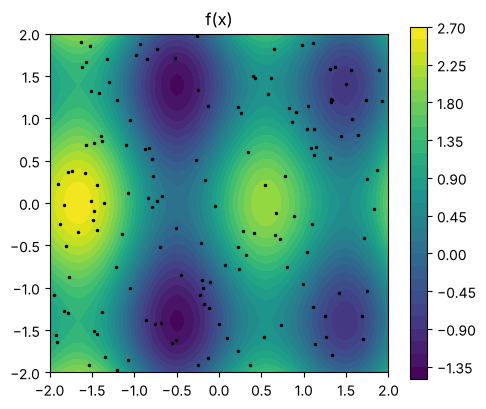

In [2]:
def f(X):
    X = np.atleast_2d(X)
    return 0.25 * (X[:, 0] ** 2 + X[:, 1] ** 2) + np.sin(3 * X[:, 0]) + np.cos(2 * X[:, 1])


BOUNDS = [(-2.0, 2.0), (-2.0, 2.0)]
rng = np.random.default_rng(42)
X = rng.uniform(-2, 2, size=(150, 2))
y = f(X) + 0.05 * rng.normal(size=len(X))

g = np.linspace(-2, 2, 301)
G1, G2 = np.meshgrid(g, g)
GRID = np.column_stack([G1.ravel(), G2.ravel()])


def grid_min(predict):
    # Brute-force minimum of a model on the 301 x 301 grid.
    values = predict(GRID)
    k = np.argmin(values)
    return values[k], GRID[k]


def show(predict, title, points=None, ax=None):
    # Contour plot of a model with optional marked points {label: x}.
    ax = ax or plt.gca()
    cs = ax.contourf(G1, G2, predict(GRID).reshape(G1.shape), levels=30, cmap="viridis")
    for (label, p), marker in zip((points or {}).items(), ["*", "o", "s", "^", "D"]):
        ax.plot(*p, marker, ms=14, mec="w", mfc="r", label=label)
    if points:
        ax.legend(loc="lower right", fontsize=8)
    ax.set_title(title)
    ax.set_aspect("equal")
    return cs


plt.figure(figsize=(5, 4.2))
plt.colorbar(show(f, "f(x)"))
plt.plot(X[:, 0], X[:, 1], "k.", ms=3)
plt.tight_layout()

## The basic workflow, with DPOSE

`DPOSE` is a shallow ensemble network: one hidden network with an output layer of
ensemble members. Its default activation is ReLU, so it can be exported as is.

`to_pyomo(input_bounds=...)` returns a Pyomo model. The input bounds are required: the
MIP encoding of each ReLU needs a finite range for its input (the big-M constants), and
`pycse` propagates the input bounds through the network to compute them. Tighter bounds
give smaller constants and faster solves.

In [3]:
from pycse.sklearn import DPOSE

dpose = DPOSE(layers=(2, 32, 16)).fit(X, y, maxiter=1000)

m = dpose.to_pyomo(input_bounds=BOUNDS)
n_binary = sum(1 for v in m.component_data_objects(pyo.Var) if v.is_binary())
print(f"{n_binary} binary variables, {m.nconstraints()} constraints")

m.obj = pyo.Objective(expr=m.y[0], sense=pyo.minimize)
result = HIGHS.solve(m)
x_mip = np.array([pyo.value(m.x[i]) for i in range(2)])
print(result.solver.termination_condition, "at x =", x_mip.round(4), "y =", round(pyo.value(m.y[0]), 4))

y_grid, x_grid = grid_min(dpose.predict)
print("grid search:          x =", x_grid.round(4), "y =", round(y_grid, 4))
print("model at the MIP x:   y =", round(float(dpose.predict(x_mip[None, :])[0]), 4))

30 binary variables, 157 constraints


optimal at x = [-0.5129  1.2494] y = -1.7826


grid search:          x = [-0.52    1.2533] y = -1.78


model at the MIP x:   y = -1.7826


The MIP optimum is at least as good as the best grid point, and evaluating the model at
the MIP solution gives the same value: the MIP is an exact copy of the trained network.
Fewer binaries are needed than there are hidden units, because the bound propagation
finds units that are always on or always off over the box.

The block holds:

- `m.x[i]`: the inputs, with the bounds you gave;
- `m.y[j]`: the predictions;
- `m.z0`, `m.z1`, ...: the outputs of each layer, and `*_on` binaries for the ReLUs;
- `m.variance[j]`: the predictive variance, for models with uncertainty (see below).

`model.mip_network()` returns the same network as numpy arrays (a
`pycse.sklearn.mip.MIPNetwork`) if you want to inspect it or use another modeling tool.

Affine W (2, 32)
ReLU
Affine W (32, 16)
Affine W (16, 1)


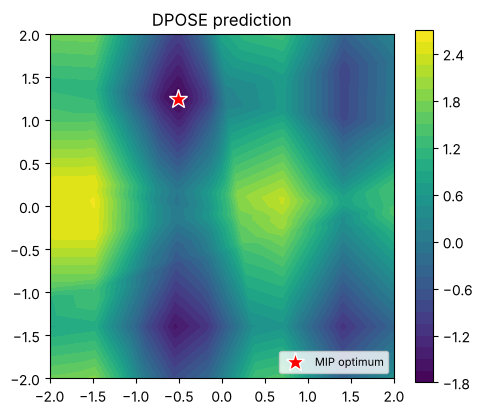

In [4]:
net = dpose.mip_network()
for layer in net.layers:
    shape = f" W {layer.W.shape}" if hasattr(layer, "W") else ""
    print(f"{type(layer).__name__}{shape}")

plt.figure(figsize=(5, 4.2))
plt.colorbar(show(dpose.predict, "DPOSE prediction", {"MIP optimum": x_mip}))
plt.tight_layout()

## Embedding the model in your own optimization problem

The real value is combining the model with other constraints and objectives. Pass
`block=` to build into a block of your own model and `inputs=` to use your own decision
variables as the model inputs; their bounds are used if you do not give `input_bounds`.

Here the inputs must satisfy a linear constraint, and the objective adds a cost on
$x_1$:

In [5]:
model = pyo.ConcreteModel()
model.a = pyo.Var(bounds=(-2, 2))
model.b = pyo.Var(bounds=(-2, 2))
model.budget = pyo.Constraint(expr=model.a + model.b >= 1.0)

model.surrogate = pyo.Block()
dpose.to_pyomo(block=model.surrogate, inputs=[model.a, model.b])

model.obj = pyo.Objective(expr=model.surrogate.y[0] + 0.3 * model.a)
HIGHS.solve(model)
print(f"a = {model.a.value:.4f}, b = {model.b.value:.4f}, objective = {pyo.value(model.obj):.4f}")

feasible = GRID[:, 0] + GRID[:, 1] >= 1.0
obj = dpose.predict(GRID) + 0.3 * GRID[:, 0]
print(f"grid search over the feasible points: {obj[feasible].min():.4f}")

a = -0.4940, b = 1.4940, objective = -1.6779


grid search over the feasible points: -1.6779


## Optimizing with uncertainty

Models with uncertainty export their predictive variance as `block.variance[j]`. For all
of them the std has the form $\sigma(x) = \sqrt{\lVert A z(x) + c \rVert^2 + d}$, where $z$ is
a layer of the network (the ensemble members for DPOSE and KfoldNN, the last-layer
features for the LLPR models). This is a second-order cone, which modern MIP solvers
handle. `to_pyomo(include_std=...)` adds a variable `block.std[j]`:

- `include_std=True` (or `"cone"`) adds the convex constraint $\text{std} \ge \sigma(x)$.
  It is exact whenever the objective *penalizes* the std, as in **robust** design:
  minimize $\mu(x) + k\,\sigma(x)$.
- `include_std="exact"` adds $\text{std}^2 = \sigma(x)^2$, a nonconvex quadratic. Use it
  when the objective *rewards* the std, as in **exploration** for active learning:
  minimize $\mu(x) - k\,\sigma(x)$ (a lower confidence bound).

HiGHS does not handle quadratic constraints, so these use Gurobi.

,objective,x1,x2,mean at x,std at x,MIP objective,grid objective,seconds
0,mean,-0.5129,1.2494,-1.7826,0.1024,-1.7826,-1.7800,0.36
1,robust: mean + 2 std,-0.4783,1.2453,-1.7693,0.0932,-1.5830,-1.5792,0.21
2,explore: mean - 2 std,-0.5193,1.2766,-1.7769,0.1076,-1.9923,-1.9900,4.21


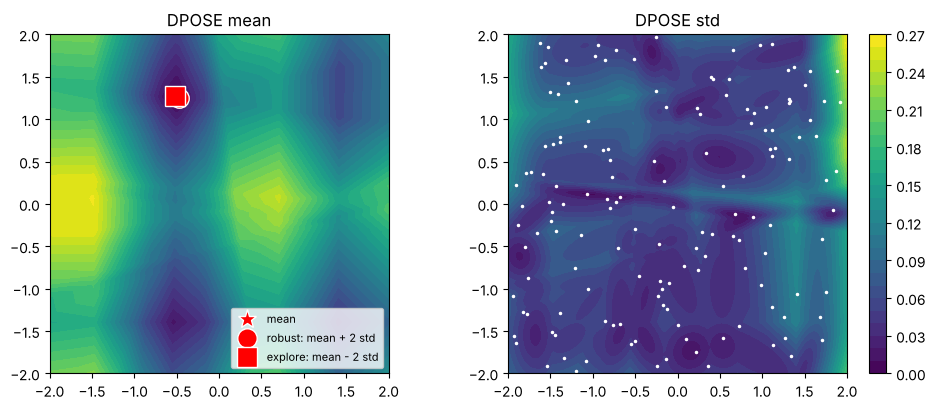

In [6]:
def solve_with_std(model, k, mode):
    m = model.to_pyomo(input_bounds=BOUNDS, include_std=mode)
    m.obj = pyo.Objective(expr=m.y[0] + k * m.std[0])
    t = time.time()
    GUROBI.solve(m)
    x = np.array([pyo.value(m.x[i]) for i in range(2)])
    return x, pyo.value(m.obj), time.time() - t


if HAVE_GUROBI:
    rows, points = [], {}
    for label, k, mode in [("mean", 0.0, "cone"), ("robust: mean + 2 std", 2.0, "cone"),
                           ("explore: mean - 2 std", -2.0, "exact")]:
        x_opt, value, seconds = solve_with_std(dpose, k, mode)
        mu, sd = dpose.predict(GRID, return_std=True)
        grid_value = (mu + k * sd).min()
        mu_x, sd_x = dpose.predict(x_opt[None, :], return_std=True)
        rows.append([label, *x_opt, mu_x[0], sd_x[0], value, grid_value, seconds])
        points[label] = x_opt
    table = pd.DataFrame(rows, columns=["objective", "x1", "x2", "mean at x", "std at x",
                                        "MIP objective", "grid objective", "seconds"])
    formats = {col: "{:.4f}" for col in table.columns[1:-1]}
    display(table.style.format({**formats, "seconds": "{:.2f}"}))

    fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
    mu, sd = dpose.predict(GRID, return_std=True)
    show(dpose.predict, "DPOSE mean", points, ax=axs[0])
    plt.colorbar(show(lambda Z: dpose.predict(Z, return_std=True)[1], "DPOSE std", ax=axs[1]))
    axs[1].plot(X[:, 0], X[:, 1], "w.", ms=3)
    plt.tight_layout()
else:
    print("Gurobi is not installed: pip install gurobipy")

In each row the MIP objective is at or below the best grid point. Penalizing the std
(robust) trades a little of the mean for a smaller std, and rewarding it (explore) trades
a little of the mean for a larger one; compare the `mean at x` and `std at x` columns. How
far the optimum moves depends on how much the std varies near the minimum of the mean,
which the right-hand plot shows.

## A tour of the exportable models

Every model in the table at the top exports the same way. Here we fit each one to the
same data, export it, and find its global minimum with HiGHS. The table reports the size
of each MIP and checks the optimum against the grid search on the same model.

In [7]:
from flax import linen as nn
from sklearn.linear_model import BayesianRidge, LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pycse.sklearn import (
    KAN, KANLLPR, NNBR, KfoldNN, LeafModelRegressor, LLPRRegressor,
)

with QUIET(io.StringIO()):
    models = {
        "DPOSE": dpose,
        "LLPRRegressor": LLPRRegressor(hidden_dims=(32, 32), activation="relu", n_epochs=300).fit(X, y),
        "NNBR": NNBR(MLPRegressor(hidden_layer_sizes=(32, 32), activation="relu", max_iter=3000, random_state=0),
                     BayesianRidge()).fit(X, y),
        "KfoldNN": KfoldNN((32, 16), xtrain=0.5, activation="relu").fit(X, y, maxiter=1000),
        "KAN": KAN(layers=(2, 4, 1), grid_size=10, spline_order=1,
                   base_activation="linear").fit(X, y, maxiter=1000),
        "KANLLPR": KANLLPR(layers=(2, 4, 1), grid_size=10, spline_order=1,
                           base_activation="linear").fit(X, y, maxiter=1000),
        "LeafModelRegressor": LeafModelRegressor(
            make_pipeline(StandardScaler(), LinearRegression()), min_samples_leaf=6).fit(X, y),
    }
# Points exactly on a tree split are ambiguous in a MIP; split_gap resolves it (see below).
OPTIONS = {"LeafModelRegressor": {"split_gap": 1e-4}}


def benchmark(name, model, **options):
    t = time.time()
    m = model.to_pyomo(input_bounds=BOUNDS, **options)
    build = time.time() - t
    m.obj = pyo.Objective(expr=m.y[0])
    t = time.time()
    HIGHS.solve(m)
    solve = time.time() - t
    x = np.array([[pyo.value(m.x[i]) for i in range(2)]])
    y_mip = pyo.value(m.y[0])
    return {
        "model": name,
        "binaries": sum(1 for v in m.component_data_objects(pyo.Var) if v.is_binary()),
        "constraints": m.nconstraints(),
        "build s": build,
        "solve s": solve,
        "MIP min": y_mip,
        "grid min": float(grid_min(model.predict)[0]),
        "|MIP - predict(x*)|": float(abs(y_mip - np.ravel(model.predict(x))[0])),
        "test RMSE": float(np.sqrt(np.mean((model.predict(GRID) - f(GRID)) ** 2))),
    }


tour = pd.DataFrame(
    [benchmark(name, model, **OPTIONS.get(name, {})) for name, model in models.items()]
)
tour.style.format({"build s": "{:.2f}", "solve s": "{:.2f}", "MIP min": "{:.4f}",
                   "grid min": "{:.4f}", "|MIP - predict(x*)|": "{:.1e}", "test RMSE": "{:.3f}"})

,model,binaries,constraints,build s,solve s,MIP min,grid min,|MIP - predict(x*)|,test RMSE
0,DPOSE,30,157,0.01,0.15,-1.7826,-1.7800,6.4e-15,0.137
1,LLPRRegressor,63,288,0.19,18.14,-1.5799,-1.5799,4.4e-16,0.424
2,NNBR,61,283,0.02,6.32,-1.4487,-1.4469,0.0e+00,0.294
3,KfoldNN,31,159,0.01,0.32,-1.7040,-1.6993,0.0e+00,0.434
4,KAN,65,94,0.75,0.86,-1.6489,-1.6341,6.2e-15,0.139
5,KANLLPR,68,101,0.02,1.66,-1.6776,-1.6699,1.6e-15,0.135
6,LeafModelRegressor,20,146,0.02,0.03,-1.3605,-1.3599,4.4e-16,0.452


In every row the MIP minimum is at or below the grid minimum, and the model evaluated at
the MIP solution agrees with the MIP value to solver precision: the exports are exact.
(The tree is exported with `split_gap`, explained in the section on trees below.)
The models differ in accuracy (the RMSE against the true function on the grid) and in MIP
size. KANs need one set of segment binaries per input of each layer, shared by all the
edges from that input. The tree needs one binary per leaf.

The minima of the different models are at different places, because each is a different
approximation of $f$:

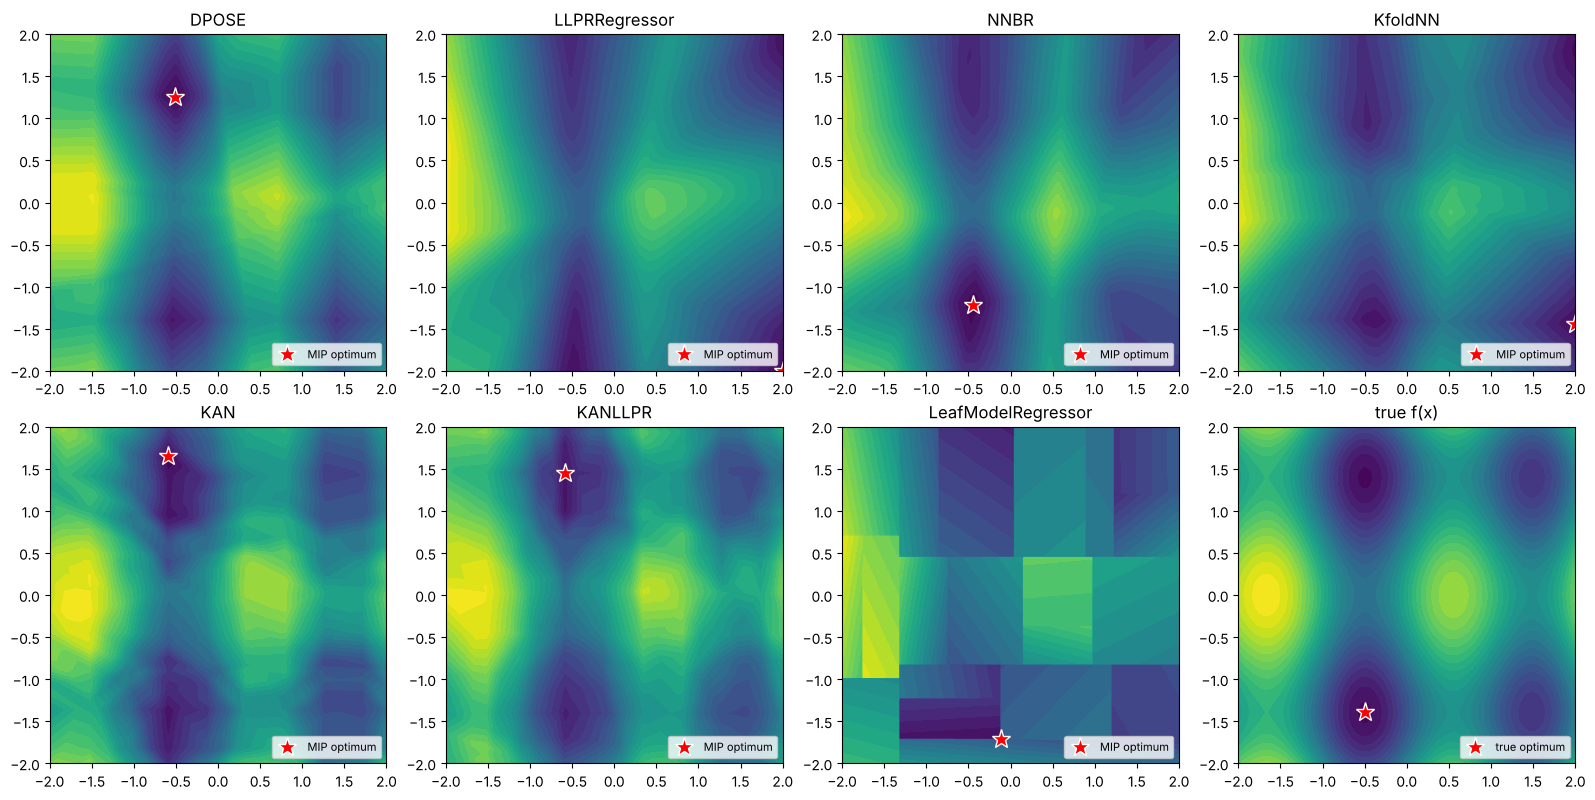

In [8]:
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, (name, model) in zip(axs.ravel(), models.items()):
    m = model.to_pyomo(input_bounds=BOUNDS, **OPTIONS.get(name, {}))
    m.obj = pyo.Objective(expr=m.y[0])
    HIGHS.solve(m)
    show(model.predict, name, {"MIP optimum": [pyo.value(m.x[0]), pyo.value(m.x[1])]}, ax=ax)
show(f, "true f(x)", {"true optimum": grid_min(f)[1]}, ax=axs[-1, -1])
plt.tight_layout()

A global optimizer is unforgiving about where a model is wrong. An optimum can sit on the
boundary of the box, where there are few training points and the model extrapolates; a
local optimizer started in the middle might never find it, but the MIP will. If that
happens, penalize the std (the robust objective above), tighten the bounds, or add
constraints that keep the inputs near the data.

## Linear models

`LinearRegressionUQ` is linear in its inputs, so it exports with no binaries at all; its
std is a second-order cone in the inputs. It fits `y = X @ coefs`, so an intercept is a
column of ones in `X`, which we fix with the bounds `(1, 1)`:

In [9]:
from pycse.sklearn import LinearRegressionUQ

Xa = np.column_stack([np.ones(len(X)), X])
lin = LinearRegressionUQ().fit(Xa, y)
m = lin.to_pyomo(input_bounds=[(1, 1), *BOUNDS])
print("binaries:", sum(1 for v in m.component_data_objects(pyo.Var) if v.is_binary()))
print("prediction at x = (0.5, -1):", lin.predict(np.array([[1, 0.5, -1]]), return_std=True))

binaries: 0
prediction at x = (0.5, -1): (array([0.22552606]), array([0.90157599]))


## Input-convex networks: an LP instead of a MIP

`JAXICNNRegressor` is constrained to be convex in its inputs (an input-convex neural
network, ICNN). With ReLU activations its output is convex and piecewise linear, and every
hidden unit enters the output with a nonnegative weight. When the output is *minimized*
(or bounded above), the ReLU constraints $z \ge 0$, $z \ge a$ alone are enough: the
solver pushes each $z$ down to $\max(0, a)$ by itself. `to_pyomo(formulation="convex")`
uses this to export the network as a **linear program with no binaries**, which solves
fast even for large networks. It checks that the network really is input-convex.

`JAXMonotonicRegressor(convexity="convex")` is input-convex too, so it can also use the LP
formulation; with the default `convexity=None` it mixes convex and concave units and
needs the MILP.

In [10]:
from pycse.sklearn import JAXICNNRegressor, JAXMonotonicRegressor


def h(X):
    # A convex function, increasing in x1.
    X = np.atleast_2d(X)
    return np.exp(0.5 * X[:, 0]) + 0.5 * (X[:, 1] - 0.5) ** 2 + 0.3 * np.abs(X[:, 0] + X[:, 1])


yh = h(X) + 0.02 * rng.normal(size=len(X))
convex_models = {
    "JAXICNNRegressor": JAXICNNRegressor(hidden_dims=(64, 64), activation="relu",
                                         epochs=300).fit(X, yh),
    "JAXMonotonicRegressor": JAXMonotonicRegressor(
        hidden_dims=(64, 64), monotonicity=[1, 0], convexity="convex", activation="relu",
        epochs=300).fit(X, yh),
}

rows = []
for name, model in convex_models.items():
    for formulation in ["bigm", "convex"]:
        row = benchmark(name, model, formulation=formulation)
        row["formulation"] = formulation
        rows.append(row)
cols = ["model", "formulation", "binaries", "constraints", "solve s", "MIP min", "grid min"]
pd.DataFrame(rows)[cols].style.format({"solve s": "{:.2f}", "MIP min": "{:.4f}", "grid min": "{:.4f}"})

,model,formulation,binaries,constraints,solve s,MIP min,grid min
0,JAXICNNRegressor,bigm,122,501,0.47,0.4869,0.4870
1,JAXICNNRegressor,convex,0,257,0.06,0.4869,0.4870
2,JAXMonotonicRegressor,bigm,128,577,0.30,0.4286,0.4287
3,JAXMonotonicRegressor,convex,0,257,0.09,0.4286,0.4287


Both formulations give the same minimum; the LP needs no binaries. The LP is only valid
for minimizing the output (or keeping it below a bound). To *maximize* an ICNN, use the
default `formulation="bigm"`.

## KANs: splines, clipping and ensembles

A KAN layer applies a learned 1D function to each edge. With `spline_order=1` these are
piecewise linear, and with `base_activation="linear"` the residual term is linear too, so
the whole network is piecewise linear. The splines are defined on `grid_range` (in
standardized units) and are constant outside it; the export represents this clipping
exactly, so the MIP is exact for any input bounds.

All edges leaving one input share that input's breakpoints, so the MIP needs one set of
segment binaries per input of each layer, not per edge. Without `input_bounds`, a KAN uses
the input range its spline grid covers.

With `n_ensemble > 1`, the prediction is the mean of the ensemble and the std is exported
as for DPOSE:

In [11]:
kan_ens = KAN(layers=(2, 4, 1), grid_size=10, spline_order=1, base_activation="linear",
              n_ensemble=4, loss_type="crps").fit(X, y, maxiter=1000)
m = kan_ens.to_pyomo()
print("default input bounds:", [tuple(round(float(b), 3) for b in m.x[i].bounds) for i in range(2)])

m = kan_ens.to_pyomo(input_bounds=BOUNDS)
x = np.array([0.3, -1.2])
for i in range(2):
    m.x[i].fix(x[i])
m.obj = pyo.Objective(expr=0)
HIGHS.solve(m)
mu, sd = kan_ens.predict(x[None, :], return_std=True)
print(f"MIP: y = {pyo.value(m.y[0]):.6f}, std = {np.sqrt(pyo.value(m.variance[0])):.6f}")
print(f"KAN: y = {mu[0]:.6f}, std = {sd[0]:.6f}")

default input bounds: [(-2.45, 2.188), (-2.283, 2.332)]


MIP: y = 0.430679, std = 0.009355
KAN: y = 0.430679, std = 0.009355


## Trees with linear leaves

`LeafModelRegressor` is a decision tree with a linear model in each leaf. In the MIP,
each leaf is a box with one binary that selects it, and the prediction is that leaf's
linear model. Leaves that do not intersect the input bounds are dropped, so narrower
bounds give a smaller MIP.

A tree sends $x \le t$ to the left at each split, and strict inequalities cannot be
written in a MIP: by default a point exactly on a split can take either neighboring
leaf's value. `split_gap` requires $x \ge t + \text{gap}$ on the right instead, which
rules this out at the cost of excluding the thin slab $(t, t + \text{gap})$. The gap has
to be well above the solver's tolerances (about $10^{-6}$).

In [12]:
tree = models["LeafModelRegressor"]
for bounds in [BOUNDS, [(0, 1), (0, 1)]]:
    m = tree.to_pyomo(input_bounds=bounds)
    print(f"bounds {bounds}: {len(m.leaf)} of {tree.get_n_leaves()} leaves in the MIP")

root_feature, t = tree.tree_.feature[0], tree.tree_.threshold[0]
x_split = np.zeros(2)
x_split[root_feature] = t
print(f"\nroot split: x{root_feature} <= {t:.4f}; predict at the split = {tree.predict(x_split[None, :])[0]:.4f}")
for gap in [0.0, 1e-4]:
    values = []
    for sense in [pyo.minimize, pyo.maximize]:
        m = tree.to_pyomo(input_bounds=BOUNDS, split_gap=gap)
        for i in range(2):
            m.x[i].fix(x_split[i])
        m.obj = pyo.Objective(expr=m.y[0], sense=sense)
        HIGHS.solve(m)
        values.append(round(pyo.value(m.y[0]), 4))
    print(f"split_gap={gap}: MIP values on the split range over {values}")

bounds [(-2.0, 2.0), (-2.0, 2.0)]: 20 of 20 leaves in the MIP
bounds [(0, 1), (0, 1)]: 6 of 20 leaves in the MIP

root split: x0 <= -1.3296; predict at the split = 2.2475


split_gap=0.0: MIP values on the split range over [1.9539, 2.2475]


split_gap=0.0001: MIP values on the split range over [2.2475, 2.2475]


## Periodic models: an approximate export with an error bound

`JAXPeriodicRegressor` expands periodic inputs into Fourier features
$\sin(2\pi h x / T)$ and $\cos(2\pi h x / T)$ before a ReLU network. The network is
piecewise linear but the features are not, so the export **interpolates** each feature
linearly on a grid over the input bounds. The rest of the network is exact.

The interpolation error of a feature with $|f''| \le \omega^2$ on a grid of spacing $h$ is at
most $\omega^2 h^2 / 8$. With `points_per_period` grid points per period of the highest
harmonic, this is $(2\pi/\text{points\_per\_period})^2/8$: about $4.8\times 10^{-3}$ for the
default 32. `mip_network().max_feature_error(bounds)` reports the bound, and
`mip_network().encoded(bounds)` is the interpolated network the MIP represents exactly.
More points cost more binaries.

In [13]:
from pycse.sklearn import JAXPeriodicRegressor


def p(X):
    # Periodic in x1 with period 2, smooth in x2.
    X = np.atleast_2d(X)
    return np.sin(np.pi * X[:, 0]) + 0.5 * np.cos(2 * np.pi * X[:, 0]) + 0.5 * X[:, 1] ** 2


Xp = np.column_stack([rng.uniform(0, 4, 200), rng.uniform(-1, 1, 200)])
yp = p(Xp) + 0.02 * rng.normal(size=len(Xp))
with QUIET(io.StringIO()):
    periodic = JAXPeriodicRegressor(hidden_dims=(16, 16), activation="relu", periodicity={0: 2.0},
                                    n_harmonics=2, epochs=500).fit(Xp, yp)

P_BOUNDS = [(0.0, 4.0), (-1.0, 1.0)]
Xt = np.column_stack([rng.uniform(0, 4, 2000), rng.uniform(-1, 1, 2000)])
rows = []
for ppp in [8, 16, 32, 64]:
    net = periodic.mip_network(points_per_period=ppp)
    m = periodic.to_pyomo(input_bounds=P_BOUNDS, points_per_period=ppp)
    m.obj = pyo.Objective(expr=m.y[0])
    t = time.time()
    HIGHS.solve(m)
    x_opt = np.array([[pyo.value(m.x[i]) for i in range(2)]])
    error = np.abs(net.encoded(P_BOUNDS).forward(Xt)[:, 0] - periodic.predict(Xt))
    rows.append({
        "points_per_period": ppp,
        "binaries": sum(1 for v in m.component_data_objects(pyo.Var) if v.is_binary()),
        "feature error bound": net.max_feature_error(P_BOUNDS)[0].max(),
        "max |MIP model - predict|": error.max(),
        "solve s": time.time() - t,
        "MIP min": pyo.value(m.y[0]),
        "predict at MIP x": float(periodic.predict(x_opt)[0]),
    })
P_GRID = np.column_stack([np.repeat(np.linspace(0, 4, 401), 201), np.tile(np.linspace(-1, 1, 201), 401)])
p_grid_min = periodic.predict(P_GRID).min()
for row in rows:
    row["predict at MIP x - grid min"] = row["predict at MIP x"] - p_grid_min
display(pd.DataFrame(rows).style.format({"feature error bound": "{:.1e}",
                                         "max |MIP model - predict|": "{:.1e}", "solve s": "{:.2f}",
                                         "MIP min": "{:.4f}", "predict at MIP x": "{:.4f}",
                                         "predict at MIP x - grid min": "{:.1e}"}))
print(f"grid search on the model: {p_grid_min:.4f}")

,points_per_period,binaries,feature error bound,max |MIP model - predict|,solve s,MIP min,predict at MIP x,predict at MIP x - grid min
0,8,64,7.7e-02,5.4e-02,1.74,-1.5224,-1.5224,2.4e-03
1,16,96,1.9e-02,1.4e-02,1.96,-1.5224,-1.5224,2.4e-03
2,32,160,4.8e-03,3.4e-03,2.57,-1.5224,-1.5224,2.4e-03
3,64,288,1.2e-03,9.7e-04,3.05,-1.5252,-1.5252,-4.5e-04


grid search on the model: -1.5248


The error of the exported model shrinks roughly by a factor of four each time the grid
density doubles, as the bound predicts. The bound is on each feature; the error in the
output also depends on the network's weights, which is why the table measures it too.

The MIP finds the global optimum of the *interpolated* model, so the true model's value
at that point (`predict at MIP x`) can be above the model's own minimum by up to about the
error: the last column compares it with a fine grid search. It shrinks as the grid gets
finer. Choose `points_per_period` so the error is well below the accuracy you need, or
refine the solution locally from the MIP optimum.

## SISSO: exact nonlinear export

`SISSO` finds an explicit equation, such as $y = c_1 x_1 x_2 + c_2 e^{x_2}/x_1 + c_0$. It is
not piecewise linear, but it does not need to be approximated: `to_pyomo()` writes the
equation itself into the Pyomo block, with Pyomo's `exp`, `log`, division and so on. The
result is an exact nonlinear program that a global MINLP solver (Gurobi, BARON, SCIP)
solves to optimality; Ipopt finds local optima. The std from `predict(return_std=True)` is
exported as an expression too. SISSO needs `pip install TorchSisso`.

In [14]:
try:
    from pycse.sklearn import SISSO

    Xs = rng.uniform(0.5, 2.0, size=(80, 2))
    ys = 2 * Xs[:, 0] * Xs[:, 1] + np.exp(Xs[:, 1]) / Xs[:, 0] + 0.01 * rng.normal(size=len(Xs))
    with QUIET(io.StringIO()):  # TorchSisso prints its progress
        sisso = SISSO(operators=["+", "-", "*", "/", "exp"], n_expansion=2, n_term=2).fit(Xs, ys)
    print("equation:", sisso.equation_)
    HAVE_SISSO = True
except ImportError as err:
    print(err)
    HAVE_SISSO = False

if HAVE_SISSO and HAVE_GUROBI_MINLP:
    S_BOUNDS = [(0.5, 2.0), (0.5, 2.0)]
    m = sisso.to_pyomo(input_bounds=S_BOUNDS, include_std=True)
    m.obj = pyo.Objective(expr=m.y[0] + 2 * m.std[0])
    pyo.SolverFactory("gurobi_direct_minlp").solve(m)
    print(f"min y + 2 std = {pyo.value(m.obj):.5f} at x = ({m.x[0].value:.4f}, {m.x[1].value:.4f})")
    gs = np.linspace(0.5, 2.0, 301)
    S_GRID = np.array(np.meshgrid(gs, gs)).reshape(2, -1).T
    mu, sd = sisso.predict(S_GRID, return_std=True)
    print(f"grid search:   {(mu + 2 * sd).min():.5f}")
elif HAVE_SISSO:
    print("A global MINLP solver is needed, e.g. pip install gurobipy")

equation:  + 3.3931917104*(x1/x0)   + 2.1516130961*(x0*x1)  -0.6118790242955567


min y + 2 std = 2.73623 at x = (1.2564, 0.5000)
grid search:   2.73623


## What cannot be exported, and why

`to_pyomo()` raises a `ValueError` that says what to change when a model is not
piecewise linear, for example a smooth activation:

In [15]:
try:
    with QUIET(io.StringIO()):
        smooth = LLPRRegressor(hidden_dims=(8,), activation="silu", n_epochs=1).fit(X, y)
    smooth.to_pyomo(input_bounds=BOUNDS)
except ValueError as err:
    print("ValueError:", err)

ValueError: MIP export requires LLPRRegressor(activation='relu') (piecewise linear); got activation='silu'.


- Smooth activations (SiLU, tanh, softplus) and cubic splines are not piecewise linear.
  Retrain with ReLU or `spline_order=1`; it usually costs little accuracy.
- `JAXICNNRegressor(strong_convexity_mu > 0)` adds a quadratic term.
- `ZENNRegressor` and `ZENNClassifier` combine their sub-networks through a log-sum-exp
  over configurations, which is neither piecewise linear nor a compact closed form.
- `NNGMM` gets its uncertainty from a Gaussian mixture; its mean network could be
  exported, but it does not implement `to_pyomo()`.

## Practical tips

- **Bounds matter.** Every input needs finite bounds; the tighter they are, the fewer
  binaries (units that are always on or off need none) and the faster the solve.
- **Size.** MIP solve time grows quickly with the number of binaries. Prefer small
  networks, KANs (binaries per input, not per unit), or the LP formulation for convex
  models. Training with `max_iter`/`epochs` large enough to converge also tends to give
  simpler, faster MIPs than a poorly trained network.
- **Scaling is handled.** Models that standardize their inputs and outputs internally
  have the scaling folded into the exported weights, so `x` and `y` are in your units.
- **Solvers.** HiGHS is free and handles the MILPs. Objectives with the std need a solver
  for quadratic constraints (Gurobi, CPLEX, SCIP), and SISSO a nonlinear one.
- **Your own tools.** `model.mip_network()` returns the network as numpy arrays (or a
  `TreeModel`/`SymbolicModel`), and `pycse.sklearn.mip.add_to_pyomo` builds the block, so
  you can also write a network you trained elsewhere as a `MIPNetwork`.